# Linnik — kernel interaction-range sweep and EP fluctuations

## Interaction range는 커널 파라미터 ell

$$\widehat K_\ell(q)=e^{-\ell q}\quad\text{(Poisson)},\qquad
\widehat K_\ell(q)=\frac{1}{1+(\ell q)^\alpha}\quad\text{(Linnik)}.$$

질문의 $e^{-a q}$에서 **a를 바꾸는 실험**이다. 코드에서는 Landau 계수 `p.a=-1`과
구분하기 위해 커널의 scale parameter를 `kernel.ell`로 부른다.
기본값은 **ell = 1, 2, 4, 8**이며, **각 ell에서 새로운 64×64 trajectory를 적분**한다.
coupling `strength=g=0.35`, Landau 계수, alpha, 평균 밀도, dt, burn/production 시간과
sampling interval을 고정한다. 커널 amplitude에 추가적인 ell 의존 재정규화를 하지 않는다.
Poisson/Linnik 모두 ell을 바꾸면 실제 drift와 그에 따른 density trajectory가 달라진다.

각 run은 같은 초기 field에서 시작하고 같은 noise seed를 쓴다. Backend 안에서 common noise
realization을 공유하는 parameter 비교이며, 결과의 CI는 **한 seed의 시간 block-bootstrap**이다.
seed 사이 변동을 추정하려면 `p.seed`를 바꿔 sweep을 반복한다.
기존 trajectory에 다른 커널을 사후 적용하거나, 거리 R까지의 기여만 잘라 새 run을 대신하지 않는다.
적분은 **Euler–Maruyama**, EP는 매 solver step의 **midpoint**를 유지한다.

## 관측량과 분해

$$\mu_C=\mu_{C,\mathrm{local}}+\sum_\rho\mu_{K,\rho},\qquad
\mu_{K,\rho}(x)=g\sum_{y:\,|x-y|\in B_\rho}w_\ell(x-y)\phi(y),$$
$$j_{K,\rho}(t_j)= -\frac{\Delta V}{D\delta t}
\sum_{n\in j,x}\mu_{K,\rho}(\phi_m)(x)\Delta\phi(x),\quad
j_{\mathrm{med},\rho}=j_{K,\rho}+\mathbf1_{\rho=0}(j_{C,\mathrm{local}}+j_A).$$

같은 source 거리 rho의 **모든 위치와 receiving phi의 signed EP를 먼저 합한 뒤**
그 신호의 variance를 구한다. rho는 중심 x에서 source y까지의 periodic 거리이다.
Kernel이 quadratic이므로 공간 합산한 midpoint EP는 정확한 quadratic boundary identity
$j_{K,\rho}=-\Delta F_{K,\rho}/(D\delta t)$로 구할 수 있다.
매 step의 active/local EP와 full-precision shell energy를 저장하고 sparse 영상 frame 차분은 쓰지 않는다.
따라서 공간 합산 EP에는 비용이 큰 phi-conditioned observer가 필요하지 않다.

아래에서는 ell별로 $\mathrm{Var}_t[j_{\mathrm{med},\rho}]$,
$\mathrm{Var}_t[j_{\mathrm{med},\rho}]/\rho^2$, PSD를 비교한다.
전체 kernel/medium EP variance는 **rho를 먼저 합한 시간 신호**에서 계산해 거리 간 covariance를 보존한다.
rho=0의 local 항은 전체 medium EP에 포함하며, rho²로 나누는 그림에서는 제외한다.

## Density 2-point scaling 비교

각 ell의 **자기 trajectory**에서 connected pair average
$C_\ell(\rho)=\langle\delta\phi(x)\delta\phi(x+r)\rangle_{x,t,|r|\in B_\rho}$를 계산한다.
같은 production window의 모든 EP sampling endpoint에서 누적한 structure power를 사용한다.
Signed C, 정규화한 $|C|$와 EP/rho² 곡선, 공통 거리 구간의 유효 slope를 비교한다.
공통 slope fit은 C의 첫 부호 변화 전에 멈춘다. C slope CI는 저장된 blockwise structure가 없어 추정하지 않는다.
EP variance에는 시간 차분된 4-point correlation과 kernel weight가 남으므로 C와 같은 지수를 전제하지 않는다.
Periodic kernel의 zero mode를 제거했으므로 signed weight의 zero crossing이 EP 곡선의 dip을 만들 수 있다.
선택 구간의 slope를 보편적인 asymptotic exponent로 해석하지 않는다.


In [1]:
from pathlib import Path
import sys
from dataclasses import asdict
ROOT=Path.cwd()
if not (ROOT/'lramb').is_dir():
    ROOT=next((q for q in [ROOT/'LRAMB',*ROOT.parents] if (q/'lramb').is_dir()),ROOT)
sys.path.insert(0,str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from lramb import Parameters,KernelSpec,backend_options
from lramb.range_sweep import (run_range_sweep,plot_range_fluctuations,
    plot_range_kernels,plot_range_scaling,plot_range_states)

KIND='linnik'
ELL_VALUES=(1.0,2.0,4.0,8.0)
p=Parameters(n=64,dx=1.0,dt=0.01,a=-1.0,b=1.0,kappa=1.0,
             lam=0.8,mobility=1.0,D=0.05,mean=-0.2,seed=17)
kernel=KernelSpec(kind=KIND,strength=0.35,ell=2.0,alpha=1.5)
BURN_STEPS=40_000
PRODUCTION_STEPS=64_000
SAMPLE_EVERY=40
FRAME_EVERY=200
BLOCKS=8
BOOTSTRAP_DRAWS=500
INITIAL_MODE='stripe'
SIMULATION=backend_options('torch',device='auto',dtype='float64')
# 'auto' selects torch on CUDA and NumPy on CPU; 'numpy' needs no PyTorch.
REUSE_CACHE=True
PER_AREA=False
AS_INCREMENT=False
FIT_RHO_MIN=2.0
FIT_RHO_MAX=16.0
OUTPUT=ROOT/'results'/f'{KIND}_ep'/'range_sweep'
OUTPUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':105,'font.size':10})
print('Actual kernel range ell:',ELL_VALUES,'; fixed g:',kernel.strength)
print('Backend:',SIMULATION,'; EP interval:',SAMPLE_EVERY*p.dt)
display(asdict(p),asdict(kernel))


Actual kernel range ell: (1.0, 2.0, 4.0, 8.0) ; fixed g: 0.35
Backend: {'backend': 'torch', 'device': 'cpu', 'dtype': 'float64'} ; EP interval: 0.4


{'n': 64,
 'dx': 1.0,
 'dt': 0.01,
 'a': -1.0,
 'b': 1.0,
 'kappa': 1.0,
 'lam': 0.8,
 'mobility': 1.0,
 'D': 0.05,
 'mean': -0.2,
 'seed': 17}

{'kind': 'linnik', 'strength': 0.35, 'ell': 2.0, 'alpha': 1.5}

## 1. 각 ell에서 새 dynamics 적분 / cache

커널, 초기 field, seed, backend, 적분 간격과 시간, solver source가 일치하는 cache만 재사용한다. 처음 실행하면 ell별 104,000 step을 적분한다. `ELL_VALUES`를 바꾸면 그 ell의 trajectory를 생성한다.

In [2]:
sweep=run_range_sweep(KIND,ells=ELL_VALUES,parameters=p,kernel=kernel,output=OUTPUT,
    burn_steps=BURN_STEPS,production_steps=PRODUCTION_STEPS,sample_every=SAMPLE_EVERY,
    frame_every=FRAME_EVERY,blocks=BLOCKS,draws=BOOTSTRAP_DRAWS,initial_mode=INITIAL_MODE,
    simulation=SIMULATION,reuse_cache=REUSE_CACHE,density=PER_AREA,increment=AS_INCREMENT,
    rho_min=FIT_RHO_MIN,rho_max=FIT_RHO_MAX)
display([{'ell':r['ell'],'kernel':r['run'].metadata['kernel'],
          'mass drift':float(np.ptp(r['run'].mass)),
          'kernel midpoint / energy residual':float(np.max(abs(
              r['series'].lr_rate.sum(axis=1)-r['run'].ep_rate[:,1]))),
          'midpoint quartic quadrature residual':r['run'].balance_error} for r in sweep])


linnik ell=1: integrating 104,000 steps (torch/cpu, g=0.35)
  saved ell=1: 131.4s
linnik ell=2: integrating 104,000 steps (torch/cpu, g=0.35)
  saved ell=2: 146.4s
linnik ell=4: integrating 104,000 steps (torch/cpu, g=0.35)
  saved ell=4: 129.2s
linnik ell=8: integrating 104,000 steps (torch/cpu, g=0.35)
  saved ell=8: 191.9s


[{'ell': 1.0,
  'kernel': {'kind': 'linnik', 'strength': 0.35, 'ell': 1.0, 'alpha': 1.5},
  'mass drift': 5.551115123125783e-17,
  'kernel midpoint / energy residual': 1.503153157500492e-11,
  'midpoint quartic quadrature residual': 4.493222646069071},
 {'ell': 2.0,
  'kernel': {'kind': 'linnik', 'strength': 0.35, 'ell': 2.0, 'alpha': 1.5},
  'mass drift': 5.551115123125783e-17,
  'kernel midpoint / energy residual': 1.3535839116229909e-11,
  'midpoint quartic quadrature residual': 4.470787054158858},
 {'ell': 4.0,
  'kernel': {'kind': 'linnik', 'strength': 0.35, 'ell': 4.0, 'alpha': 1.5},
  'mass drift': 5.551115123125783e-17,
  'kernel midpoint / energy residual': 1.0976108910654148e-11,
  'midpoint quartic quadrature residual': 4.584162062880189},
 {'ell': 8.0,
  'kernel': {'kind': 'linnik', 'strength': 0.35, 'ell': 8.0, 'alpha': 1.5},
  'mass drift': 5.551115123125783e-17,
  'kernel midpoint / energy residual': 6.859846024553917e-12,
  'midpoint quartic quadrature residual': 5.0575

## 2. Kernel과 실제 density structure 변화

ell에 따른 momentum/real-space kernel과 각 trajectory의 C(rho), S(q)를 비교한다. strength는 고정이며 표시한 real-space kernel은 zero mode를 제거한 periodic signed kernel이다.

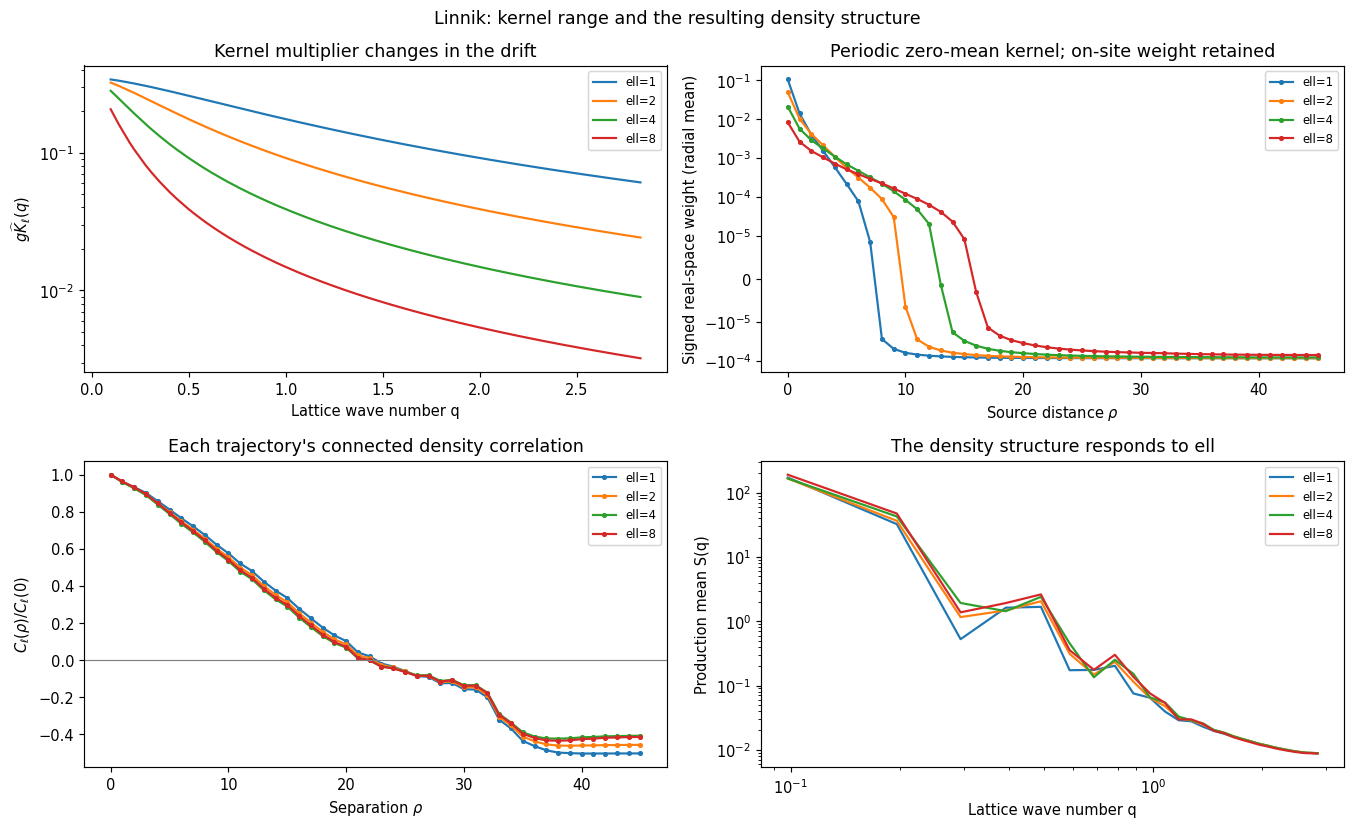

In [3]:
fig_kernels=plot_range_kernels(sweep,OUTPUT)
plt.show()


## 3. 실제 interaction range ell에 따른 kernel-decomposed EP fluctuation

각 ell에서 rho별 signed 공간 합의 variance와 variance/rho²를 그린다. rho/ell 축도 함께 보되 amplitude는 추가 정규화하지 않는다. 고정 rho의 fluctuation 및 전체 kernel/medium EP variance·PSD도 ell별로 비교한다. Shading은 시간 block-bootstrap 95% interval이다.

[{'ell': 1.0,
  'variance total medium': 33791.03097687692,
  'variance total kernel': 545.1093546867123,
  'variance local active': 1190.0685418481385},
 {'ell': 2.0,
  'variance total medium': 33774.76543206486,
  'variance total kernel': 378.97307736963586,
  'variance local active': 1362.3047967637642},
 {'ell': 4.0,
  'variance total medium': 33975.09747176166,
  'variance total kernel': 219.1425814169245,
  'variance local active': 1571.3633081862997},
 {'ell': 8.0,
  'variance total medium': 34481.30786732499,
  'variance total kernel': 98.24185804676137,
  'variance local active': 1742.5885015735191}]

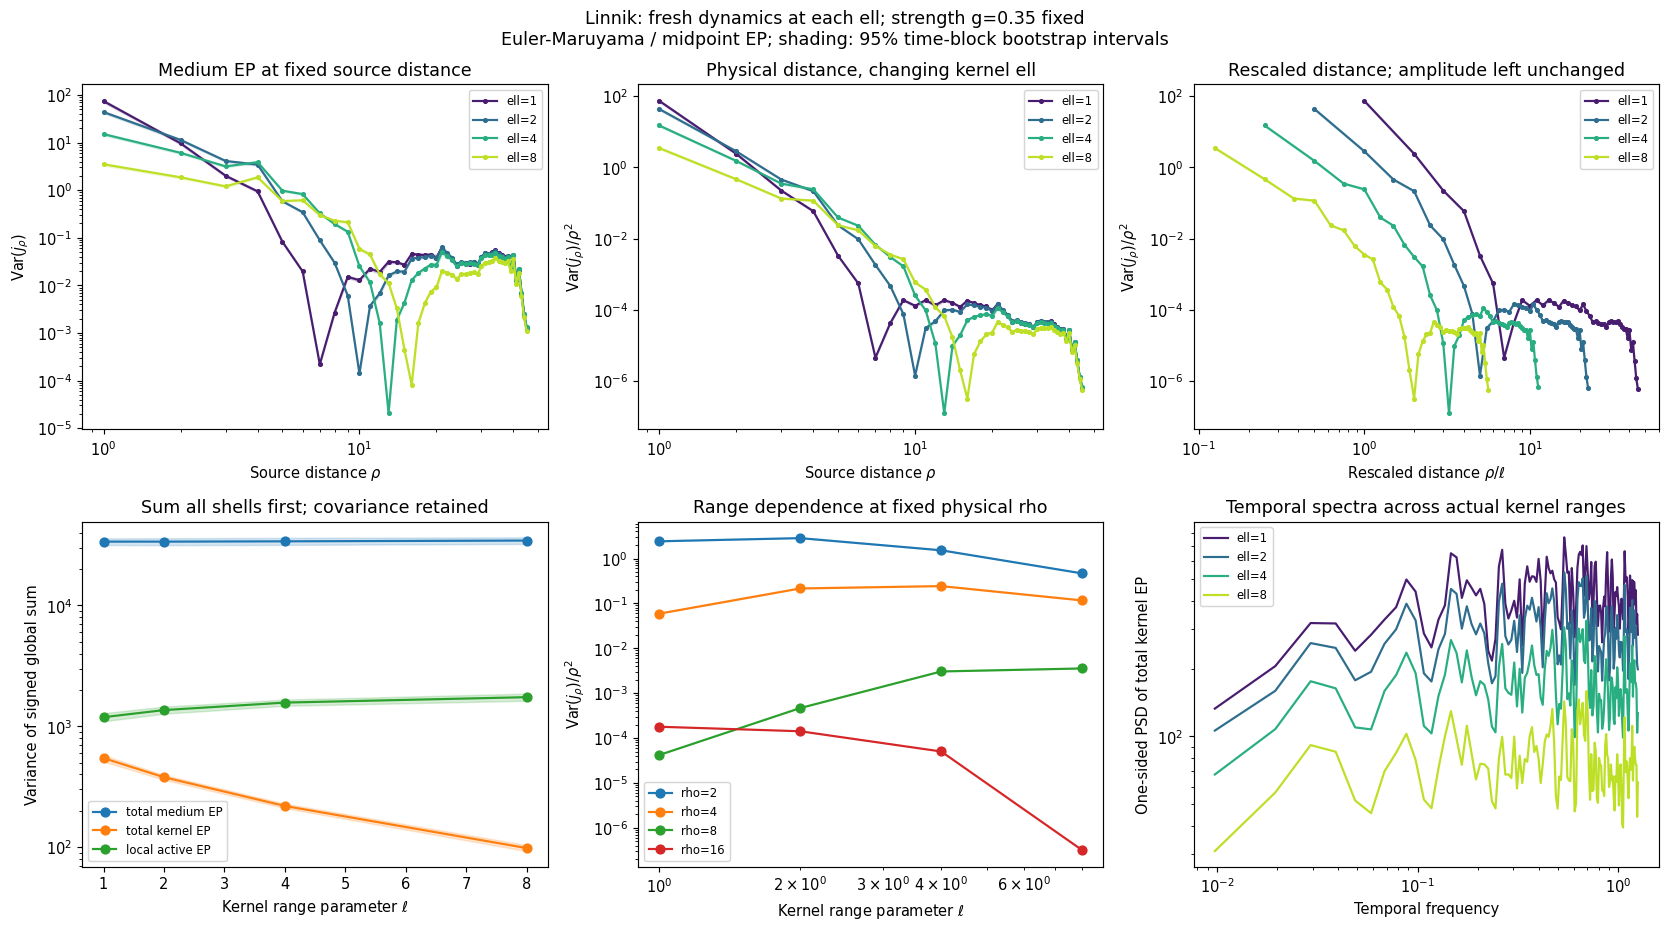

In [4]:
fig_ep=plot_range_fluctuations(sweep,OUTPUT)
display([{'ell':r['ell'],'variance total medium':float(r['global_stats']['variance'][0]),
          'variance total kernel':float(r['global_stats']['variance'][1]),
          'variance local active':float(r['global_stats']['variance'][3])} for r in sweep])
plt.show()


## 4. Ell별 EP/rho²와 density 2-point scaling 비교

두 관측량은 첫 selected rho에서 정규화해 모양과 slope를 비교한다. C의 부호를 marker로 표시하고, 각 ell의 공통 fit 구간을 함께 출력한다.

[{'ell': 1.0,
  'rho': [2.0,
   3.0,
   4.0,
   5.0,
   6.0,
   7.0,
   8.0,
   9.0,
   10.0,
   11.0,
   12.0,
   13.0,
   14.0,
   15.0,
   16.0],
  'ep_variance_over_rho2_slope': -4.643816268516367,
  'ep_slope_ci95': [-4.676732771390731, -4.615489522219843],
  'two_point_abs_slope': -0.5495696702476097,
  'slope_difference': -4.094246598268757},
 {'ell': 2.0,
  'rho': [2.0,
   3.0,
   4.0,
   5.0,
   6.0,
   7.0,
   8.0,
   9.0,
   10.0,
   11.0,
   12.0,
   13.0,
   14.0,
   15.0,
   16.0],
  'ep_variance_over_rho2_slope': -5.976538265972803,
  'ep_slope_ci95': [-6.0120635078327505, -5.947346551675381],
  'two_point_abs_slope': -0.5849841554797464,
  'slope_difference': -5.391554110493056},
 {'ell': 4.0,
  'rho': [2.0,
   3.0,
   4.0,
   5.0,
   6.0,
   7.0,
   8.0,
   9.0,
   10.0,
   11.0,
   12.0,
   13.0,
   14.0,
   15.0,
   16.0],
  'ep_variance_over_rho2_slope': -6.810412546179078,
  'ep_slope_ci95': [-6.843085782376255, -6.784017390163425],
  'two_point_abs_slope': -0.6260

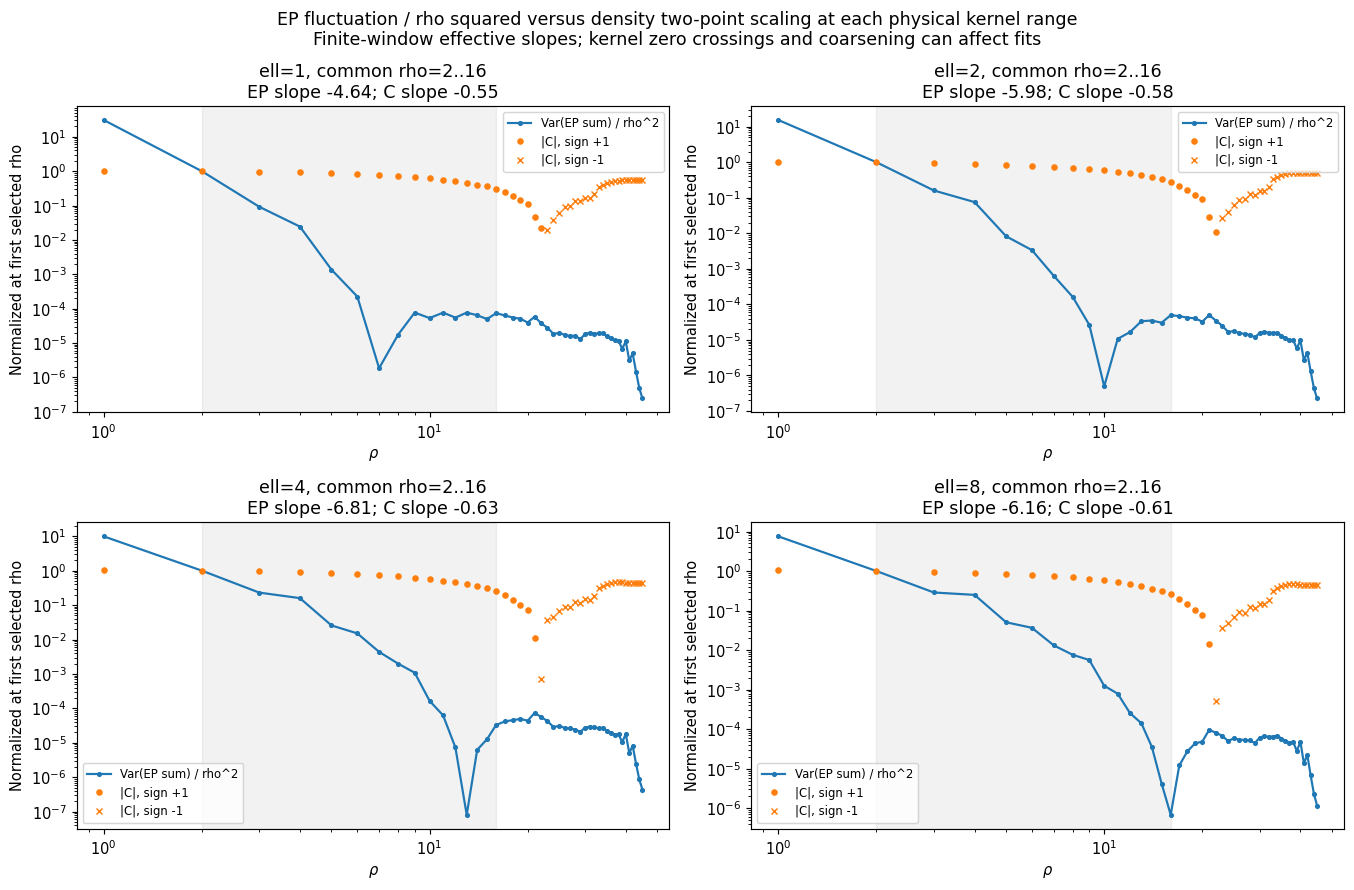

In [5]:
fig_scaling=plot_range_scaling(sweep,OUTPUT)
display([{'ell':r['ell'],**r['scaling']['report']['common_sign_branch']} for r in sweep])
plt.show()


## 5. 관측 구간과 steady-state 진단

동일한 시간이 모든 ell에서 같은 equilibration 정도를 보장하지 않는다. 최종 field, Var(phi), 구조의 mean q와 각 ell의 stationarity report를 함께 확인한다. Drift가 남으면 이 결과는 finite-window 비교이며 `BURN_STEPS`와 production 시간을 늘려 다시 계산한다.

ell = 1.0
ell = 2.0
ell = 4.0
ell = 8.0


[{'observable': 'F_C / area',
  'mean': -0.06816028800599043,
  'block_se': 0.00014363055410030384,
  'drift': 0.0010049154457276999,
  'drift_ci95': 0.0005807266179447552,
  'drift_detected': True},
 {'observable': 'Var(phi)',
  'mean': 0.47877846712447575,
  'block_se': 0.002384802398882459,
  'drift': -0.01800803610942367,
  'drift_ci95': 0.006868791281998576,
  'drift_detected': True},
 {'observable': 'mean q (S-weighted)',
  'mean': 0.19415141827514634,
  'block_se': 0.0005287097443827484,
  'drift': 0.004133355054392518,
  'drift_ci95': 0.001084336128073312,
  'drift_detected': True},
 {'observable': 'active EP / area',
  'mean': 0.0445433631459157,
  'block_se': 0.0002106377211375512,
  'drift': -0.00025099177473772785,
  'drift_ci95': 0.0016821899873774519,
  'drift_detected': False}]

[{'observable': 'F_C / area',
  'mean': -0.07307728209592622,
  'block_se': 0.00022796517681895255,
  'drift': 0.0017186080224009085,
  'drift_ci95': 0.0006638584233247031,
  'drift_detected': True},
 {'observable': 'Var(phi)',
  'mean': 0.48556238656101414,
  'block_se': 0.0030113835722555015,
  'drift': -0.02353438576478194,
  'drift_ci95': 0.006206633694250613,
  'drift_detected': True},
 {'observable': 'mean q (S-weighted)',
  'mean': 0.20101814488702754,
  'block_se': 0.0007697594822409823,
  'drift': 0.0061206023086447766,
  'drift_ci95': 0.0011169311465144805,
  'drift_detected': True},
 {'observable': 'active EP / area',
  'mean': 0.048289296963288646,
  'block_se': 0.00023306307193811016,
  'drift': -8.575705814681141e-05,
  'drift_ci95': 0.0018798928983830916,
  'drift_detected': False}]

[{'observable': 'F_C / area',
  'mean': -0.08487780155017195,
  'block_se': 0.0003446819108223194,
  'drift': 0.0026839637725547373,
  'drift_ci95': 0.0007464121465357264,
  'drift_detected': True},
 {'observable': 'Var(phi)',
  'mean': 0.5118160581645369,
  'block_se': 0.0036964084809354703,
  'drift': -0.029309513741555944,
  'drift_ci95': 0.005793052012420372,
  'drift_detected': True},
 {'observable': 'mean q (S-weighted)',
  'mean': 0.204605020958177,
  'block_se': 0.0010122395908959527,
  'drift': 0.008096512556446445,
  'drift_ci95': 0.001177280693405074,
  'drift_detected': True},
 {'observable': 'active EP / area',
  'mean': 0.051785905172889536,
  'block_se': 0.0002613273282978573,
  'drift': 0.0001878390600633465,
  'drift_ci95': 0.002101700884644306,
  'drift_detected': False}]

[{'observable': 'F_C / area',
  'mean': -0.10781767116035865,
  'block_se': 0.0003110161474892167,
  'drift': 0.002394325061946527,
  'drift_ci95': 0.0007653327468386405,
  'drift_detected': True},
 {'observable': 'Var(phi)',
  'mean': 0.575492250161766,
  'block_se': 0.003168021992583238,
  'drift': -0.02483656061149775,
  'drift_ci95': 0.0062267639907959416,
  'drift_detected': True},
 {'observable': 'mean q (S-weighted)',
  'mean': 0.19690641046391016,
  'block_se': 0.0007109508927123132,
  'drift': 0.005656969613792487,
  'drift_ci95': 0.0010096314726242442,
  'drift_detected': True},
 {'observable': 'active EP / area',
  'mean': 0.05332180992865661,
  'block_se': 0.00025936639280060836,
  'drift': 3.7173060943234554e-05,
  'drift_ci95': 0.0020938980180726084,
  'drift_detected': False}]

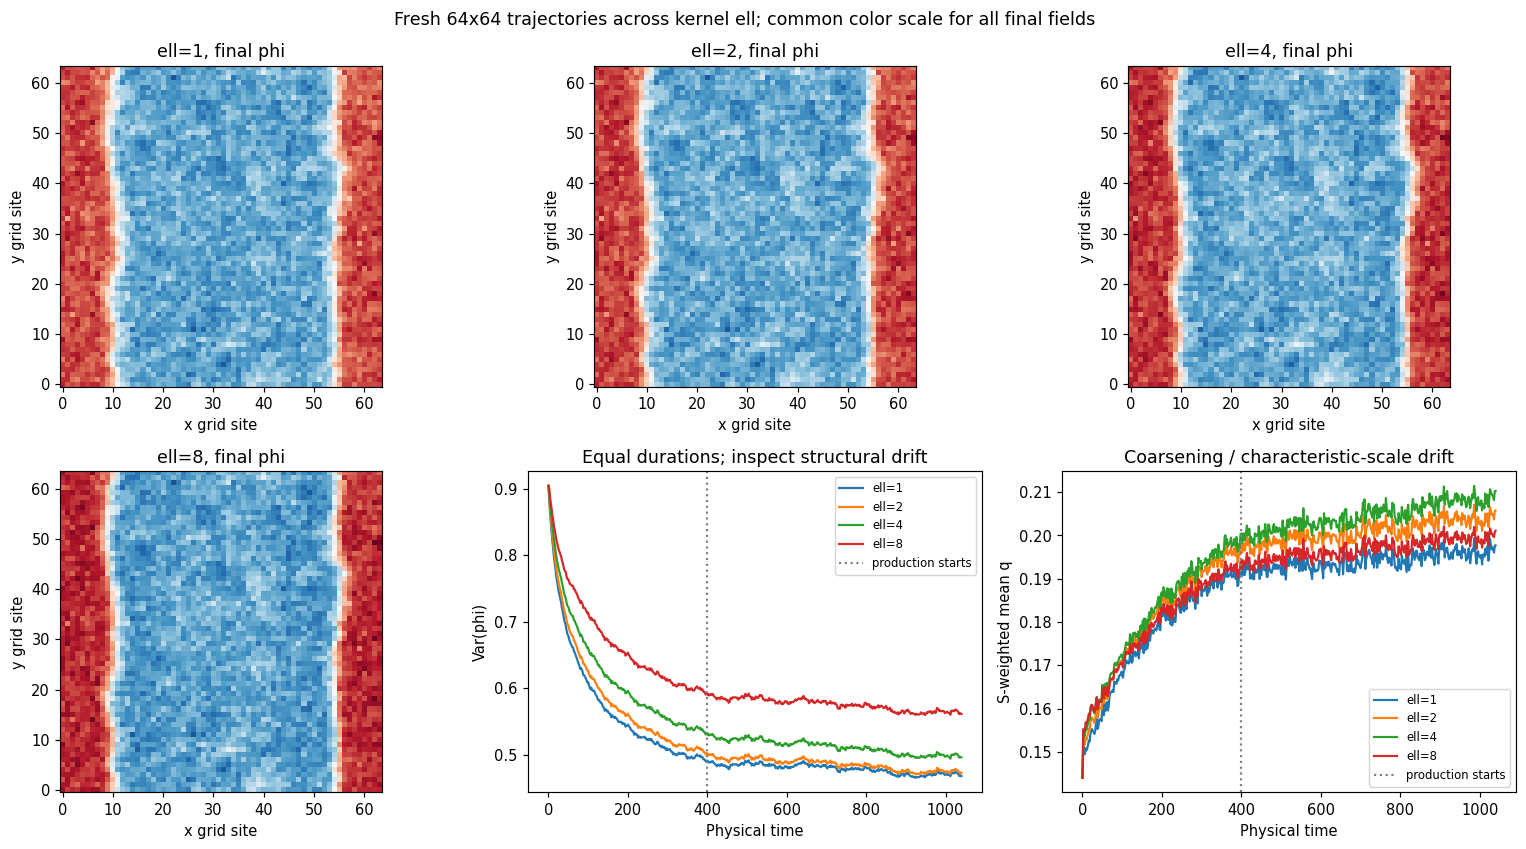

In [6]:
fig_states=plot_range_states(sweep,OUTPUT)
for r in sweep:
    print('ell =',r['ell'])
    display(r['stationarity'])
plt.show()


## 저장 결과

`results/<kernel>_ep/range_sweep/ell_<ell>/`에 각 ell의 trajectory와 rho EP 분석 NPZ를 저장한다. Sweep 폴더의 `range_sweep.npz/json`에 ell별 variance/CI, C, 전체 EP PSD, 수치 프로토콜과 drift/slope 진단이 들어간다. 네 개의 비교 그림도 PNG로 저장한다.

Riesz의 `(ell*q)^(-alpha)`에서 ell 변화는 coupling amplitude 변경이므로 별도 `riesz_ep.ipynb`는 단일 커널의 rho별 fluctuation 분석을 유지한다.